# 2.27 · Entropy and information: how much did the data teach us?

**Before this:** [2.03](2-03_probability_distributions.ipynb) (distributions), [2.08](2-08_bayesian_linear_map.ipynb) (Bayesian linear inversion; section 4 uses its posterior covariance), [2.06](2-06_matrix_primer.ipynb) (SVD)  
**You will be able to:** count uncertainty in bits; compute before measuring how much a datum or a network can teach;
read a per-patch information map; say why the Gaussian and the half-normal are maximum-entropy choices  
**Optional sections:** 5 (maximum entropy)

An inversion returns a posterior. A natural next question is: compared with what we knew before, how much did the
data actually tell us, and about what? **Entropy** puts a number on how uncertain a distribution is, and
**information gain** puts a number on how much a measurement reduced that uncertainty. Both are counted in *bits*,
the same unit as in computing, and the counting turns out to be very concrete: one bit is one yes/no question
answered, or one halving of an uncertainty.

**Words this notebook defines:** entropy, bit, nat, differential entropy, joint entropy, information gain,
mutual information, signal-to-noise ratio, maximum-entropy distribution.

**Problems in this notebook**

| problem | unknowns | data | forward model | linear? |
|---|---|---|---|---|
| a patch slips or not; a die (section 1) | 1 discrete outcome | none | none | none |
| one slip value seen by one GPS displacement (section 3) | 1 | 1 | $d = G\,s$ + noise | linear |
| antiplane fault of notebook 2.33 (section 4) | 30 patches | 24 stations | screw-dislocation Green's functions, $\mathbf d = \mathbf G\mathbf s$ | linear |
| maximum-entropy shapes (section 5) | one distribution on a grid of 150-280 cells | 1-2 constraints | none | none |

In [1]:
import sys, pathlib, heapq
sys.path.insert(0, str(pathlib.Path.cwd().parent))

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy.special import kv, gamma
from scipy.stats import norm
import jax, jax.numpy as jnp

import bayeskit as bk
from bayeskit import style as S

rng = np.random.default_rng(4)
LOG2E = 1 / np.log(2)                      # bits per nat
C4 = [S.BLUE, S.ORANGE, S.AQUA, S.VIOLET]  # categorical palette for several items in one panel


def H_bits(p):
    """Shannon entropy of a discrete distribution, in bits."""
    p = np.asarray(p, float)
    p = p[p > 0]
    return float(-np.sum(p * np.log2(p))) + 0.0      # + 0.0 turns -0.0 into 0.0

## 1. Entropy: the average number of yes/no questions

**In plain words.** Suppose a friend knows the outcome of something and you may only ask yes/no questions. The
entropy of the distribution is the smallest *average* number of questions you need to find out. A fair coin needs one
question. A fair die needs a little more than two and a half on average. If a fault patch slips in nine earthquakes
out of ten, one single earthquake still takes one question to settle without error: a guess is not knowledge. But if
you must learn the outcomes of many earthquakes, you can ask cleverly about groups of them ("did it slip in all of
the next ten?"), and the average number of questions *per earthquake* falls well below one. Entropy is the limit of
that average. It measures uncertainty: zero when the outcome is certain, largest when every outcome is equally likely.

**Precisely.** For outcomes with probabilities $p_1,\dots,p_n$ the (Shannon 1948) entropy is

$$H(p) = -\sum_{i=1}^{n} p_i \log_2 p_i \quad\text{bits},$$

with $0 \le H \le \log_2 n$: zero only for a certain outcome, $\log_2 n$ only for the uniform distribution. With the
natural logarithm the unit is the *nat* (1 nat = 1.443 bits). The question-counting meaning is a theorem of source
coding, the mathematics of compressing messages: the best possible yes/no questioning scheme for one outcome at a time (a Huffman code) needs on average $L$
questions with $H \le L < H + 1$; asking about blocks of $k$ independent outcomes at once brings the average per
outcome down to between $H$ and $H + 1/k$, so $H$ is reached only in the limit of many outcomes.

saved figures/2-27_discrete_entropy.png


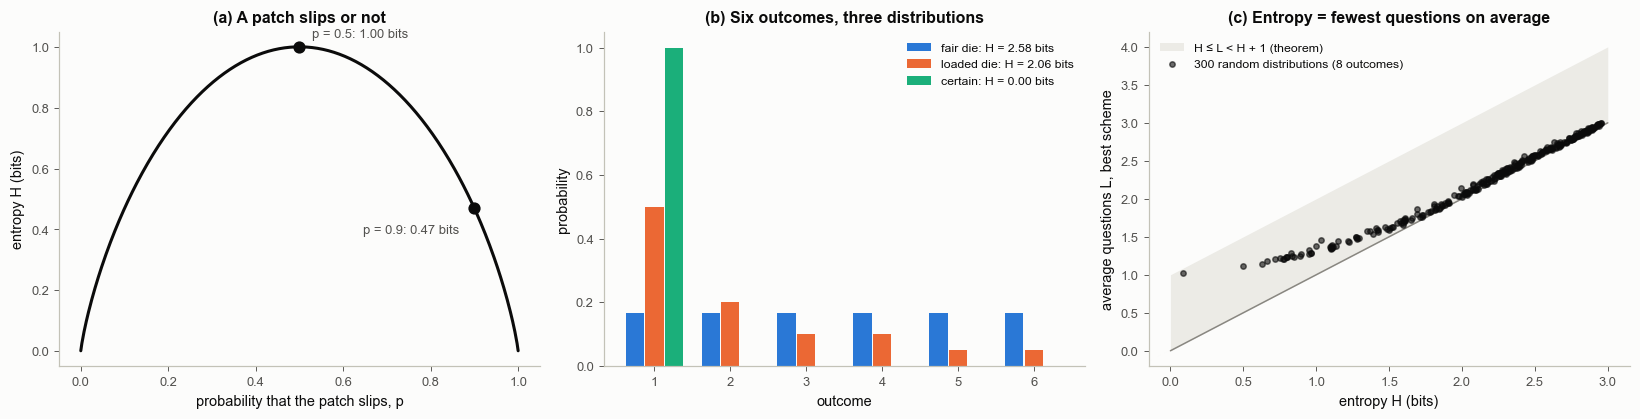

all 300 distributions satisfy H <= L < H + 1: True


In [2]:
def huffman_lengths(p):
    """Number of yes/no questions an optimal (Huffman) scheme asks for each outcome."""
    heap = [(pi, i, (i,)) for i, pi in enumerate(p)]
    heapq.heapify(heap)
    L, cnt = np.zeros(len(p)), len(p)
    while len(heap) > 1:
        a, b = heapq.heappop(heap), heapq.heappop(heap)
        for i in a[2] + b[2]:
            L[i] += 1
        heapq.heappush(heap, (a[0] + b[0], cnt, a[2] + b[2]))
        cnt += 1
    return L


pp = np.linspace(1e-4, 1 - 1e-4, 400)
dists = {"fair die": np.full(6, 1 / 6), "loaded die": np.array([0.5, 0.2, 0.1, 0.1, 0.05, 0.05]),
         "certain": np.array([1.0, 0, 0, 0, 0, 0])}
sims = []
for _ in range(300):
    p_ = rng.dirichlet(np.full(8, rng.choice([0.2, 0.5, 1.0, 3.0])))
    sims.append((H_bits(p_), float(np.sum(p_ * huffman_lengths(p_)))))
sims = np.array(sims)

fig, axs = plt.subplots(1, 3, figsize=(15, 3.9))
ax = axs[0]
ax.plot(pp, [H_bits([q, 1 - q]) for q in pp], color=S.INK, lw=2)
for q in (0.5, 0.9):
    ax.plot(q, H_bits([q, 1 - q]), "o", color=S.INK, ms=7)
    ax.annotate(f"p = {q}: {H_bits([q, 1 - q]):.2f} bits", (q, H_bits([q, 1 - q])), textcoords="offset points",
                xytext=(-10 if q == 0.9 else 8, -16 if q == 0.9 else 6), fontsize=8.5, color=S.INK2, ha="right" if q == 0.9 else "left")
ax.set_xlabel("probability that the patch slips, p"); ax.set_ylabel("entropy H (bits)")
ax.set_title("(a) A patch slips or not")
ax = axs[1]
w = 0.26
for k, (name, p_) in enumerate(dists.items()):
    ax.bar(np.arange(1, 7) + (k - 1) * w, p_, width=w * 0.92, color=C4[k], label=f"{name}: H = {H_bits(p_):.2f} bits")
ax.set_xlabel("outcome"); ax.set_ylabel("probability")
ax.set_title("(b) Six outcomes, three distributions")
ax.legend(fontsize=8, loc="upper right")
ax = axs[2]
hh = np.linspace(0, 3, 10)
ax.fill_between(hh, hh, hh + 1, color="#ecebe6", lw=0, label="H ≤ L < H + 1 (theorem)")
ax.plot(hh, hh, color=S.MUTED, lw=1)
ax.plot(sims[:, 0], sims[:, 1], "o", color=S.INK, ms=3.5, alpha=0.6, label="300 random distributions (8 outcomes)")
ax.set_xlabel("entropy H (bits)"); ax.set_ylabel("average questions L, best scheme")
ax.set_title("(c) Entropy = fewest questions on average")
ax.legend(fontsize=8, loc="upper left")
fig.tight_layout()
bk.savefig(fig, "2-27_discrete_entropy")
plt.show()
print("all 300 distributions satisfy H <= L < H + 1:", bool(np.all((sims[:, 1] >= sims[:, 0] - 1e-12) & (sims[:, 1] < sims[:, 0] + 1))))

**How to read it.** (a) A patch that slips half the time carries one full bit of uncertainty; the more predictable
its behaviour, the less you need to ask, on average over many outcomes. (b) The same six outcomes can carry very different uncertainty. (c) Each dot
is one random distribution: its entropy against the average number of questions of the best possible questioning
scheme. Every dot lies in the band between $H$ and $H+1$.

**Worked example.** The patch that slips with probability 0.9 contributes two terms, $-0.9\log_2 0.9$ and
$-0.1\log_2 0.1$. For the loaded die, the best scheme asks few questions about likely outcomes and more about rare
ones; its average is compared with $H$ below. Last, the patch again: one earthquake at a time needs one question each;
grouping $k$ earthquakes and asking the best questions about the group (a Huffman code on the $2^k$ joint outcomes)
brings the average per earthquake towards $H$.

In [3]:
q = 0.9
t1, t2 = -q * np.log2(q), -(1 - q) * np.log2(1 - q)
print(f"patch: -0.9 log2 0.9 = {t1:.4f},  -0.1 log2 0.1 = {t2:.4f},  H = {t1 + t2:.4f} bits")
print(f"fair die: H = log2 6 = {np.log2(6):.4f} bits")
p_ = dists["loaded die"]
L_ = huffman_lengths(p_)
print("loaded die:  outcome  probability  questions (best scheme)")
for i in range(6):
    print(f"                {i + 1}       {p_[i]:.2f}         {int(L_[i])}")
print(f"average questions L = {np.sum(p_ * L_):.3f};  entropy H = {H_bits(p_):.3f} bits")
print("patch with p = 0.9, questions per earthquake when k earthquakes are settled together (best scheme):")
for k in (1, 2, 4, 8, 12):
    nslip = np.array([bin(i).count("1") for i in range(2 ** k)])
    pk = q ** nslip * (1 - q) ** (k - nslip)                       # probability of each joint outcome
    print(f"   k = {k:2d}: {np.sum(pk * huffman_lengths(pk)) / k:.3f}   (entropy {t1 + t2:.3f})")

patch: -0.9 log2 0.9 = 0.1368,  -0.1 log2 0.1 = 0.3322,  H = 0.4690 bits
fair die: H = log2 6 = 2.5850 bits
loaded die:  outcome  probability  questions (best scheme)
                1       0.50         1
                2       0.20         3
                3       0.10         3
                4       0.10         3
                5       0.05         4
                6       0.05         4
average questions L = 2.100;  entropy H = 2.061 bits
patch with p = 0.9, questions per earthquake when k earthquakes are settled together (best scheme):
   k =  1: 1.000   (entropy 0.469)
   k =  2: 0.645   (entropy 0.469)
   k =  4: 0.493   (entropy 0.469)
   k =  8: 0.476   (entropy 0.469)
   k = 12: 0.470   (entropy 0.469)


**Common misreadings.**
* Entropy is a property of a *distribution*, that is, of what we know. It says nothing about disorder in the Earth.
* Entropy ignores the outcome values: a die labelled 1-6 and one labelled 10-60 have the same entropy.

## 2. Continuous quantities: differential entropy

**In plain words.** Slip in metres can take infinitely many values, so knowing it *exactly* would take infinitely many
questions. What stays meaningful is the number of questions needed to know it *to a given precision*, and above all
how that number changes when data arrive. For a Gaussian, every halving of the standard deviation removes one
question: one bit.

**Precisely.** For a density $p(x)$ the differential entropy is $H(p) = -\int p(x)\log_2 p(x)\,dx$. For a Gaussian,

$$H\big(N(\mu,\sigma^2)\big) = \tfrac12\log_2(2\pi e\,\sigma^2),\qquad H\big(N(\boldsymbol\mu,\mathbf C)\big) = \tfrac12\log_2\det(2\pi e\,\mathbf C).$$

Here $\det\mathbf C$, the determinant of the covariance matrix (reminder: 2.03 for covariance, 2.06 for the
determinant and its logarithm), is the product of its eigenvalues, i.e. the factor by which $\mathbf C$ scales
volumes: it measures the volume of the uncertainty ellipse, so a smaller ellipse means fewer bits.

Unlike the discrete case it can be negative, and it depends on the units: rewriting metres as millimetres multiplies
$\sigma$ by 1000 and adds $\log_2 1000$ bits. Cutting $x$ into bins of width $\Delta$ gives a discrete distribution
with entropy $\approx H(p) + \log_2(1/\Delta)$, the questions needed to know $x$ to within one bin.

saved figures/2-27_differential_entropy.png


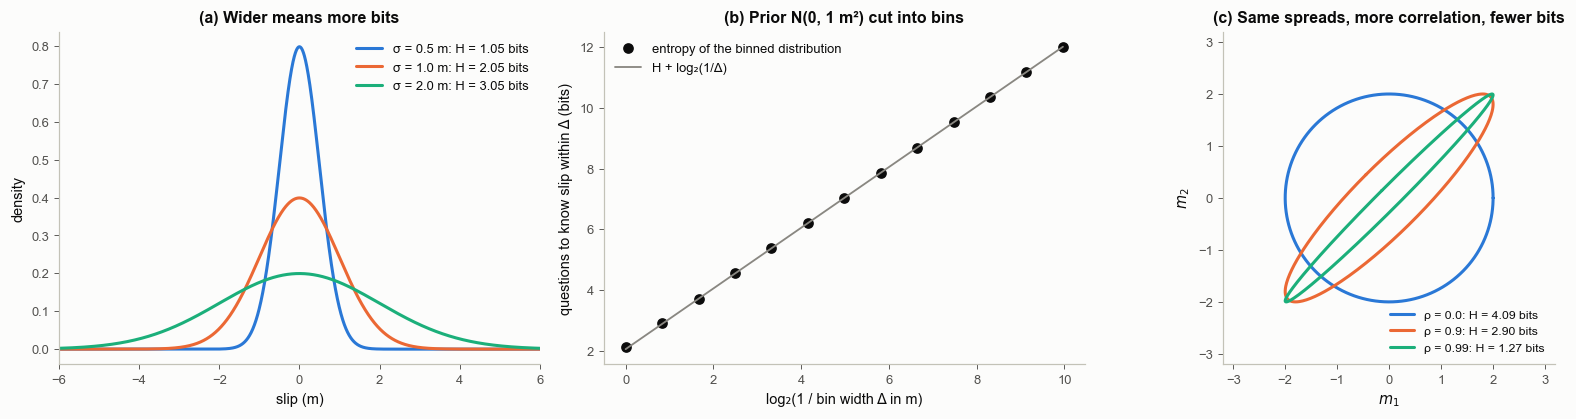

In [4]:
xg = np.linspace(-8, 8, 4001)
sigmas = [0.5, 1.0, 2.0]
Hg = lambda s: 0.5 * np.log2(2 * np.pi * np.e * s ** 2)
deltas = np.logspace(0, -3, 13)
Hdisc = []
for dlt in deltas:                                   # discretise N(0, 1) into bins of width delta
    edges = np.arange(-10, 10 + dlt, dlt)
    pb = np.diff(norm.cdf(edges))
    Hdisc.append(H_bits(pb))
Hdisc = np.array(Hdisc)
rhos = [0.0, 0.9, 0.99]

fig, axs = plt.subplots(1, 3, figsize=(15, 3.9))
ax = axs[0]
for k, s_ in enumerate(sigmas):
    ax.plot(xg, norm.pdf(xg, 0, s_), color=C4[k], lw=2, label=f"σ = {s_} m: H = {Hg(s_):.2f} bits")
ax.set_xlim(-6, 6); ax.set_xlabel("slip (m)"); ax.set_ylabel("density")
ax.set_title("(a) Wider means more bits")
ax.legend(fontsize=8.5)
ax = axs[1]
ax.plot(np.log2(1 / deltas), Hdisc, "o", color=S.INK, ms=6, label="entropy of the binned distribution")
ax.plot(np.log2(1 / deltas), Hg(1.0) + np.log2(1 / deltas), color=S.MUTED, lw=1.2, label="H + log₂(1/Δ)")
ax.set_xlabel("log₂(1 / bin width Δ in m)"); ax.set_ylabel("questions to know slip within Δ (bits)")
ax.set_title("(b) Prior N(0, 1 m²) cut into bins")
ax.legend(fontsize=8.5, loc="upper left")
ax = axs[2]
th = np.linspace(0, 2 * np.pi, 300)
for k, rho in enumerate(rhos):
    C = np.array([[1, rho], [rho, 1]])
    ev, U = np.linalg.eigh(C)
    pts = U @ (np.sqrt(ev)[:, None] * np.vstack([np.cos(th), np.sin(th)])) * 2
    ax.plot(pts[0], pts[1], color=C4[k], lw=2,
            label=f"ρ = {rho}: H = {0.5 * np.log2(np.linalg.det(2 * np.pi * np.e * C)):.2f} bits")
ax.set_aspect("equal"); ax.set_xlim(-3.2, 3.2); ax.set_ylim(-3.2, 3.2)
ax.set_xlabel("$m_1$"); ax.set_ylabel("$m_2$")
ax.set_title("(c) Same spreads, more correlation, fewer bits")
ax.legend(fontsize=8, loc="lower right")
fig.tight_layout()
bk.savefig(fig, "2-27_differential_entropy")
plt.show()

**How to read it.** (a) Doubling the standard deviation adds one bit. (b) The questions needed to pin slip down to a
bin of width $\Delta$ grow by one bit per halving of $\Delta$; the dots follow the line $H + \log_2(1/\Delta)$ once the
bins are narrower than the spread. (c) Two parameters with the same individual spreads: the more they are correlated
(a trade-off), the smaller the area of the ellipse and the fewer bits it takes to describe the pair. A trade-off means
the data have pinned down a combination.

**Worked example.** Prior slip $N(0, 1\,\text{m}^2)$ and a posterior with standard deviation 0.25 m. The entropies
change with the units; the difference does not.

In [5]:
for unit, scale in [("m", 1.0), ("mm", 1000.0)]:
    Hp, Hq = Hg(1.0 * scale), Hg(0.25 * scale)
    print(f"in {unit:2s}: H(prior) = {Hp:7.3f} bits, H(posterior) = {Hq:7.3f} bits, information gain = {Hp - Hq:.3f} bits")
print(f"changing m to mm adds log2(1000) = {np.log2(1000):.3f} bits to each entropy")

in m : H(prior) =   2.047 bits, H(posterior) =   0.047 bits, information gain = 2.000 bits
in mm: H(prior) =  12.013 bits, H(posterior) =  10.013 bits, information gain = 2.000 bits
changing m to mm adds log2(1000) = 9.966 bits to each entropy


**Common misreadings.**
* A negative differential entropy is not an error; it just means the distribution is narrower than one unit.
* Only *differences* of differential entropy (information gains) have a unit-free meaning.

## 3. Information gain: what one measurement teaches

**In plain words.** One GPS displacement $d$ sees one slip value $s$ through a sensitivity $G$ (millimetres of
displacement per metre of slip) and has noise $\sigma_d$. If the signal the slip could produce ($G$ times the prior
spread $\sigma_m$) is large compared with the noise, the measurement teaches many bits; if it is smaller than the
noise, it teaches almost nothing. Each bit gained halves the standard deviation.

**Precisely.** With prior $s \sim N(0, \sigma_m^2)$ and $d = G s + e$, $e \sim N(0, \sigma_d^2)$, the posterior variance is
$\tilde\sigma^2 = (1/\sigma_m^2 + G^2/\sigma_d^2)^{-1}$ and the entropy reduction is

$$I = H(\text{prior}) - H(\text{posterior}) = \tfrac12\log_2\!\Big(1 + \frac{G^2\sigma_m^2}{\sigma_d^2}\Big)\ \text{bits}.$$

$G\sigma_m/\sigma_d$ is a signal-to-noise ratio. In a linear-Gaussian problem the posterior width does not depend on
the value measured, so $I$ depends only on $G$, $\sigma_m$ and $\sigma_d$ and can be computed before measuring. It is
the **expected information gain**, also called the **mutual information** between $s$ and $d$: the average, over the
data the experiment could produce, of what one datum teaches. The information delivered by one *particular* datum is
measured by $D_{KL}(\text{posterior}\,\|\,\text{prior})$, the Kullback-Leibler divergence: a number for how different
two distributions are, zero only when they are equal (notebook 2.28 defines it). That also counts how far the datum moved
the posterior mean, so it varies from datum to datum and only its average equals $I$ (checked below).

In [6]:
# the 30-patch antiplane fault of notebook 2.33, rebuilt here
N = 30
z_edges = np.linspace(0.0, 30.0, N + 1)
zc = 0.5 * (z_edges[1:] + z_edges[:-1])                       # patch centres (km)
xs0 = np.array([1, 2, 3, 4, 6, 9, 13, 18, 25, 35, 50, 70.0])
xs = np.sort(np.r_[-xs0, xs0])                                # 24 stations (km from the fault)
SIG_D, SIG_M = 3.0, 1.0                                       # data noise (mm), prior slip sd (m)


def G_of(x):
    """Green's functions (mm of displacement per m of slip) for stations at x, all 30 patches."""
    x = np.atleast_1d(x)[:, None]
    return 1000.0 * (np.arctan(z_edges[None, 1:] / x) - np.arctan(z_edges[None, :-1] / x)) / np.pi


G = G_of(xs)
picks = {"shallow patch (0.5 km)": 0, "mid-depth patch (11.5 km)": 11, "deep patch (29.5 km)": 29}
s_true, rng_w = 0.6, np.random.default_rng(1)
print("one measurement, at the station that sees the patch best (prior sd 1 m, noise 3 mm):")
print(f"{'patch':28s} {'G (mm/m)':>9s} {'SNR':>7s} {'posterior sd (m)':>17s} {'gain (bits)':>12s}")
wex = {}
for name, j in picks.items():
    g = np.abs(G[:, j]).max()
    snr = g * SIG_M / SIG_D
    sd_post = 1 / np.sqrt(1 / SIG_M ** 2 + g ** 2 / SIG_D ** 2)
    gain = 0.5 * np.log2(1 + snr ** 2)
    dobs = g * s_true + SIG_D * rng_w.standard_normal()
    wex[name] = dict(g=g, snr=snr, sd=sd_post, gain=gain, mean=sd_post ** 2 * g * dobs / SIG_D ** 2)
    print(f"{name:28s} {g:9.1f} {snr:7.2f} {sd_post:17.4f} {gain:12.2f}")
print("check: log2(prior sd / posterior sd) equals the gain:",
      bool(np.allclose([np.log2(SIG_M / v['sd']) for v in wex.values()], [v['gain'] for v in wex.values()])))


def kl_post_prior_bits(mu, sd):
    """KL( N(mu, sd^2) || N(0, SIG_M^2) ) in bits: what one particular datum delivered."""
    return LOG2E * (np.log(SIG_M / sd) + (sd ** 2 + mu ** 2) / (2 * SIG_M ** 2) - 0.5)


print("\nrealised information of single data (KL posterior||prior, bits) vs the expected gain I, mid-depth patch:")
v = wex["mid-depth patch (11.5 km)"]
for dd in (-20.0, 0.0, 20.0):
    mu_ = v["sd"] ** 2 * v["g"] * dd / SIG_D ** 2
    print(f"   datum {dd:6.1f} mm: posterior mean {mu_:7.3f} m, KL = {kl_post_prior_bits(mu_, v['sd']):.3f} bits   (I = {v['gain']:.3f})")
s_draw = SIG_M * rng_w.standard_normal(200_000)                 # data the experiment could produce (s from the prior)
d_draw = v["g"] * s_draw + SIG_D * rng_w.standard_normal(s_draw.size)
kl_draw = kl_post_prior_bits(v["sd"] ** 2 * v["g"] * d_draw / SIG_D ** 2, v["sd"])
print(f"   average KL over 200,000 simulated data: {kl_draw.mean():.3f} bits (sampled; Monte Carlo se {kl_draw.std() / np.sqrt(kl_draw.size):.3f})")

one measurement, at the station that sees the patch best (prior sd 1 m, noise 3 mm):
patch                         G (mm/m)     SNR  posterior sd (m)  gain (bits)
shallow patch (0.5 km)           250.0   83.33            0.0120         6.38
mid-depth patch (11.5 km)         13.7    4.58            0.2133         2.23
deep patch (29.5 km)               5.3    1.77            0.4910         1.03
check: log2(prior sd / posterior sd) equals the gain: True

realised information of single data (KL posterior||prior, bits) vs the expected gain I, mid-depth patch:
   datum  -20.0 mm: posterior mean  -1.389 m, KL = 2.933 bits   (I = 2.229)
   datum    0.0 mm: posterior mean   0.000 m, KL = 1.540 bits   (I = 2.229)
   datum   20.0 mm: posterior mean   1.389 m, KL = 2.933 bits   (I = 2.229)
   average KL over 200,000 simulated data: 2.227 bits (sampled; Monte Carlo se 0.002)


saved figures/2-27_one_measurement.png


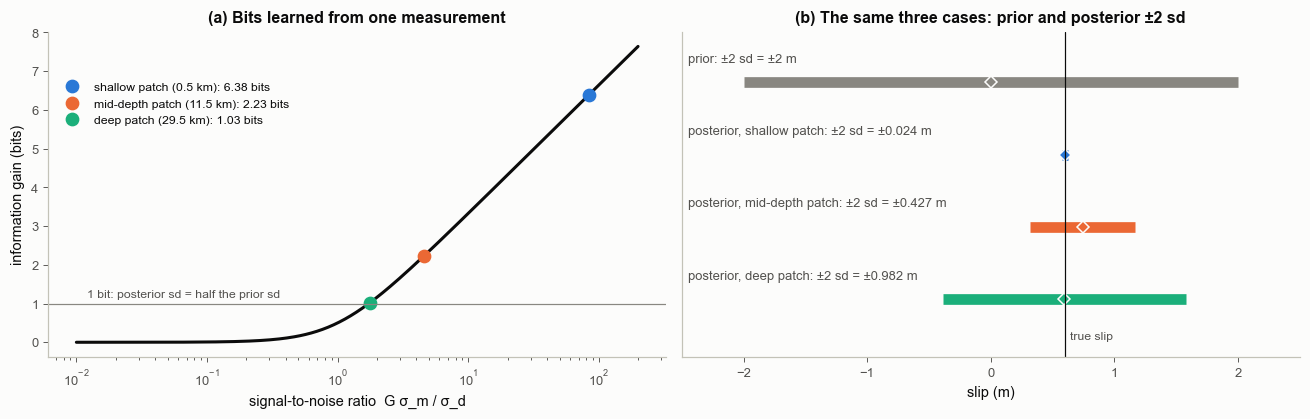

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(12, 3.9))
ax = axs[0]
snr = np.logspace(-2, 2.3, 300)
ax.semilogx(snr, 0.5 * np.log2(1 + snr ** 2), color=S.INK, lw=2)
for k, (name, v) in enumerate(wex.items()):
    ax.plot(v["snr"], v["gain"], "o", color=C4[k], ms=8, label=f"{name}: {v['gain']:.2f} bits")
ax.axhline(1, color=S.MUTED, lw=0.8)
ax.text(0.012, 1.15, "1 bit: posterior sd = half the prior sd", fontsize=8, color=S.INK2)
ax.set_xlabel("signal-to-noise ratio  G σ_m / σ_d"); ax.set_ylabel("information gain (bits)")
ax.set_title("(a) Bits learned from one measurement")
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(0.0, 0.88))
ax = axs[1]
rows = [("prior", 0.0, SIG_M, S.MUTED)] + [(f"posterior, {n.split(' (')[0]}", v["mean"], v["sd"], C4[k])
                                          for k, (n, v) in enumerate(wex.items())]
for i, (lab, mu, sd, col) in enumerate(rows):
    y = len(rows) - 1 - i
    ax.plot([mu - 2 * sd, mu + 2 * sd], [y, y], color=col, lw=7, solid_capstyle="butt")
    ax.plot(mu, y, "D", color=col, ms=6, mec=S.SURFACE, mew=1)   # visible even when the bar is very short
    ax.text(-2.45, y + 0.28, f"{lab}: ±2 sd = ±{2 * sd:.3g} m", fontsize=8.5, color=S.INK2)
ax.axvline(s_true, color=S.INK, lw=0.8)
ax.text(s_true + 0.04, -0.55, "true slip", fontsize=8, color=S.INK2)
ax.set_xlim(-2.5, 2.5); ax.set_ylim(-0.8, len(rows) - 0.3)
ax.set_yticks([])
ax.set_xlabel("slip (m)")
ax.set_title("(b) The same three cases: prior and posterior ±2 sd")
fig.tight_layout()
bk.savefig(fig, "2-27_one_measurement")
plt.show()

**How to read it.** (a) Below a signal-to-noise ratio of about 1 a measurement teaches almost nothing; above it, every
doubling of the ratio adds about one bit. The shallow patch is seen strongly by the nearest station; the deep patch
barely rises above the noise. (b) The same three cases as ±2 sd intervals, each posterior from one simulated datum
of a true slip of 0.6 m: many bits means a short bar.

## 4. Information in a whole inversion: 30 patches, 24 stations

**In plain words.** With many unknowns, the data do not teach each patch separately. They teach certain *combinations*
of patches very well and others not at all. Counting bits makes this precise: the total information splits into
independent "directions" (patterns of slip), and only a few of them carry most of the bits. Bits per patch are still
a useful map of where the data looked, but they do not add up to the total.

**Precisely.** For $\mathbf d = \mathbf G\mathbf m + \mathbf e$ with prior covariance $\mathbf C_m$ and noise covariance
$\mathbf C_d$, the posterior covariance is $\tilde{\mathbf C}_m = (\mathbf C_m^{-1} + \mathbf G^\top\mathbf C_d^{-1}\mathbf G)^{-1}$ (reminder:
2.08 derives it) and the total expected information gain (the *mutual information* between $\mathbf m$ and
$\mathbf d$, section 3) is

$$I = \tfrac12\log_2\frac{\det\mathbf C_m}{\det\tilde{\mathbf C}_m} = \sum_i \tfrac12\log_2\!\big(1 + s_i^2\big),$$

where $s_i$ are the singular values of $\mathbf C_d^{-1/2}\mathbf G\,\mathbf C_m^{1/2}$, the Green's function matrix written
in noise units on the data side and prior units on the slip side (reminders: singular values and the SVD, 2.06;
whitening by $\mathbf C_d^{-1/2}$, 2.06): each singular direction is a one-measurement problem of section 3 with
signal-to-noise ratio $s_i$. The gain for patch $j$ alone is $\tfrac12\log_2(C_{m,jj}/\tilde C_{m,jj})$. Two priors
are compared: independent patches with sd 1 m, and a Matérn prior (length scale ℓ = 5 km, smoothness ν = 1, sd 1 m;
reminder: the Matérn covariance correlates neighbouring patches over about ℓ, 2.09 and 2.12).

In [8]:
def matern(z, ell, nu=1.0, amp=1.0):
    d_ = np.abs(z[:, None] - z[None, :])
    u = np.sqrt(2 * nu) * d_ / ell
    with np.errstate(invalid="ignore"):
        K = amp ** 2 * (2 ** (1 - nu) / gamma(nu)) * u ** nu * kv(nu, u)
    K[d_ == 0] = amp ** 2
    return K + 1e-10 * np.eye(len(z))


priors = {"independent patches (sd 1 m)": np.eye(N) * SIG_M ** 2, "Matérn ℓ = 5 km, ν = 1 (sd 1 m)": matern(zc, 5.0)}
info = {}
for name, Cm in priors.items():
    Cpost = np.linalg.inv(np.linalg.inv(Cm) + G.T @ G / SIG_D ** 2)
    per_patch = 0.5 * np.log2(np.diag(Cm) / np.diag(Cpost))
    total = 0.5 * (np.linalg.slogdet(Cm)[1] - np.linalg.slogdet(Cpost)[1]) * LOG2E
    Lc = np.linalg.cholesky(Cm)
    U_, s_, Vt = np.linalg.svd(G @ Lc / SIG_D)
    per_dir = 0.5 * np.log2(1 + s_ ** 2)
    info[name] = dict(Cpost=Cpost, per_patch=per_patch, total=total, per_dir=per_dir,
                      patterns=(Lc @ Vt.T)[:, :3], ratio=np.sqrt(np.diag(Cpost) / np.diag(Cm)))
    print(f"{name}:")
    print(f"   total information gain            {total:6.2f} bits  (sum over singular directions {per_dir.sum():.2f})")
    print(f"   sum of the 30 per-patch gains     {per_patch.sum():6.2f} bits")
    print(f"   directions carrying more than 1 bit: {np.sum(per_dir > 1)};  the largest five: {np.round(per_dir[:5], 2)}")
    print(f"   per-patch gain: shallowest {per_patch[0]:.2f} bits, at 15 km {per_patch[14]:.2f}, deepest {per_patch[-1]:.2f}")

independent patches (sd 1 m):
   total information gain             23.79 bits  (sum over singular directions 23.79)
   sum of the 30 per-patch gains       7.77 bits
   directions carrying more than 1 bit: 5;  the largest five: [7.62 6.1  4.78 3.2  1.63]
   per-patch gain: shallowest 3.62 bits, at 15 km 0.06, deepest 0.09
Matérn ℓ = 5 km, ν = 1 (sd 1 m):
   total information gain             26.25 bits  (sum over singular directions 26.25)
   sum of the 30 per-patch gains      40.66 bits
   directions carrying more than 1 bit: 5;  the largest five: [8.72 7.01 5.26 3.42 1.54]
   per-patch gain: shallowest 4.67 bits, at 15 km 1.02, deepest 0.53


saved figures/2-27_fault_information.png


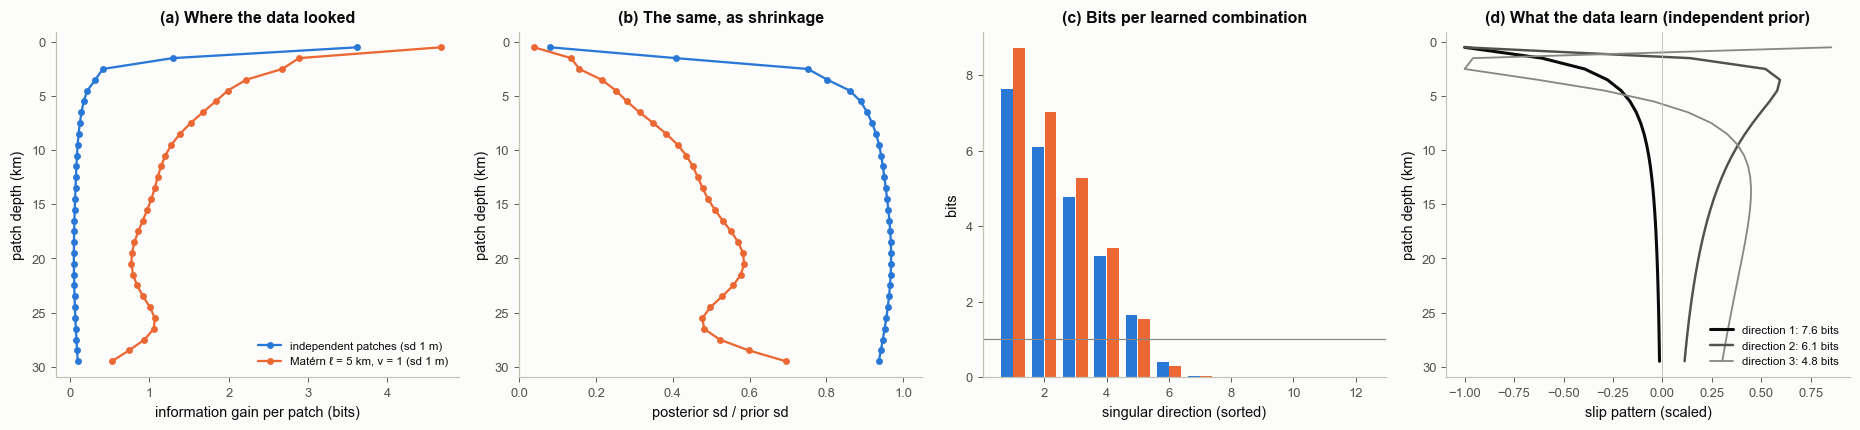

In [9]:
fig, axs = plt.subplots(1, 4, figsize=(17, 4.0))
for k, (name, v) in enumerate(info.items()):
    axs[0].plot(v["per_patch"], zc, "o-", color=C4[k], ms=3.5, lw=1.5, label=name)
    axs[1].plot(v["ratio"], zc, "o-", color=C4[k], ms=3.5, lw=1.5, label=name)
    axs[2].bar(np.arange(1, 13) + (k - 0.5) * 0.4, v["per_dir"][:12], width=0.38, color=C4[k], label=name)
for ax in axs[:2]:
    ax.invert_yaxis(); ax.set_ylabel("patch depth (km)")
axs[0].set_xlabel("information gain per patch (bits)"); axs[0].set_title("(a) Where the data looked")
axs[1].set_xlabel("posterior sd / prior sd"); axs[1].set_title("(b) The same, as shrinkage"); axs[1].set_xlim(0, 1.05)
axs[0].legend(fontsize=7.5, loc="lower right")
axs[2].axhline(1, color=S.MUTED, lw=0.8)
axs[2].set_xlabel("singular direction (sorted)"); axs[2].set_ylabel("bits")
axs[2].set_title("(c) Bits per learned combination")
ax = axs[3]
v = info["independent patches (sd 1 m)"]
for i in range(3):
    pat = v["patterns"][:, i]
    pat = pat / np.abs(pat).max()
    ax.plot(pat, zc, color=[S.INK, S.INK2, S.MUTED][i], lw=2 - 0.4 * i, label=f"direction {i + 1}: {v['per_dir'][i]:.1f} bits")
ax.axvline(0, color=S.AXIS, lw=0.6)
ax.invert_yaxis(); ax.set_xlabel("slip pattern (scaled)"); ax.set_ylabel("patch depth (km)")
ax.set_title("(d) What the data learn (independent prior)")
ax.legend(fontsize=7.5, loc="lower right")
fig.tight_layout()
bk.savefig(fig, "2-27_fault_information")
plt.show()

**How to read it.** (a) and (b) are two views of the same thing: per-patch information gain is large near the
surface and small at depth, and the posterior sd shrinks accordingly. (c) The total splits into singular directions,
and only a handful carry more than one bit (compare notebook 2.33, where only a few singular values of $\mathbf G$ rise
above the noise). (d) The best-learned combinations are smooth patterns: the first is confined to the top few
kilometres, later ones reach deeper and carry fewer bits. The data
constrain *weighted sums* of slip, mostly shallow slip, not individual deep patches.

The printed numbers show the non-additivity both ways. With independent patches the per-patch gains sum to *less*
than the total, because much of what the data teach is about combinations, which no single patch owns. With the
Matérn prior they sum to *more* than the total, because neighbouring patches share the same information and each
claims it. Only the total is a count of bits.

### Where should the next station go?

Because the gain needs only $\mathbf G$, $\mathbf C_m$ and $\mathbf C_d$, it can be computed for a station that does not
exist yet. Adding one station at distance $x$ adds $\tfrac12\log_2(1 + \mathbf g^\top\tilde{\mathbf C}_m\mathbf g/\sigma_d^2)$
bits, where $\mathbf g$ is its row of Green's functions (what that station would see per metre of slip on each patch;
2.06) and $\tilde{\mathbf C}_m$ the current posterior covariance (independent-patch prior). The term
$\mathbf g^\top\tilde{\mathbf C}_m\mathbf g$ is the variance of the new station's predicted displacement under the current
posterior: the station is worth most where the network is still most uncertain about what it would record.

largest gain in the range searched: at 0.20 km from the fault (the closest candidate), 3.24 bits
   at   0.5 km: 2.16 bits
   at   1.0 km: 0.29 bits
   at   5.0 km: 0.15 bits
   at  30.0 km: 0.09 bits
   at 100.0 km: 0.06 bits
saved figures/2-27_station_design.png


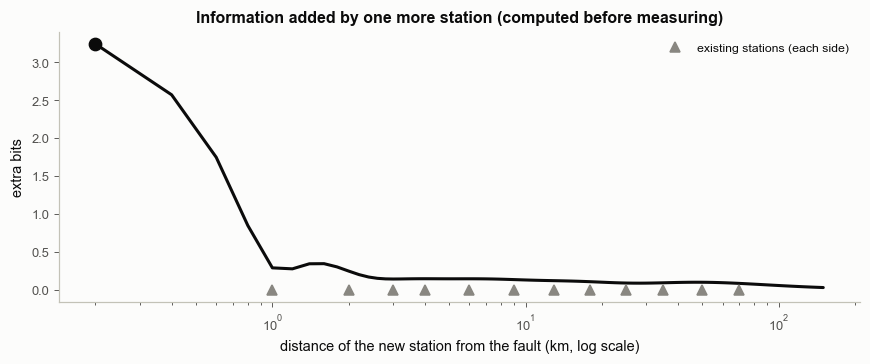

In [10]:
Cpost0 = info["independent patches (sd 1 m)"]["Cpost"]
xcand = np.r_[np.linspace(0.2, 3.0, 15), np.geomspace(3.2, 150, 70)]
extra = np.array([0.5 * np.log2(1 + G_of(x)[0] @ Cpost0 @ G_of(x)[0] / SIG_D ** 2) for x in xcand])
ib = int(np.argmax(extra))
print(f"largest gain in the range searched: at {xcand[ib]:.2f} km from the fault (the closest candidate), {extra[ib]:.2f} bits")
for x_ in (0.5, 1.0, 5.0, 30.0, 100.0):
    print(f"   at {x_:5.1f} km: {np.interp(x_, xcand, extra):.2f} bits")

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.semilogx(xcand, extra, color=S.INK, lw=2)
ax.plot(xs0, np.full(xs0.size, 0), "^", color=S.MUTED, ms=7, clip_on=False, label="existing stations (each side)")
ax.plot(xcand[ib], extra[ib], "o", color=S.INK, ms=8)
ax.set_xlabel("distance of the new station from the fault (km, log scale)"); ax.set_ylabel("extra bits")
ax.set_title("Information added by one more station (computed before measuring)")
ax.legend(fontsize=8)
fig.tight_layout()
bk.savefig(fig, "2-27_station_design")
plt.show()

The gain keeps rising toward the fault trace (the closest candidate searched is the largest), because a station
there sees the shallowest patch, which no existing station resolves completely. Beyond a few kilometres a new station
mostly repeats what the network already knows. In a real design study the same calculation compares candidate land
or seafloor sites with your own Green's functions and noise levels.

**Common misreadings.**
* "A patch gained almost no bits, so the data know nothing about it." The data may know a combination that involves
  it; per-patch gains do not add up to the total.
* "Information gain measures fit." It does not involve the residuals at all in the linear-Gaussian case; it measures
  how much the data *can* teach, given $\mathbf G$, the prior and the noise.

## 5. Maximum entropy: the most honest distribution for what you know

**In plain words.** When you must write down a prior or a noise model but know only a few facts (a range, an average,
a spread), choose the distribution with the most entropy among those that respect the facts. Any other choice
quietly assumes extra knowledge that you do not have. This principle (Jaynes 1957) produces the familiar families:
a range only gives the uniform distribution, a positive quantity with a known mean gives the exponential, a known mean
and variance give the Gaussian, a known mean absolute deviation gives the Laplace distribution (the prior behind L1
regularisation, 2.09), and a positive quantity with a known mean square gives the half-normal.

**Precisely.** Maximising $H(p)$ subject to $\int p = 1$ and $\int f_k(x)\,p(x)\,dx = c_k$ gives
$p(x) \propto \exp\big(\sum_k \lambda_k f_k(x)\big)$, with the $\lambda_k$ set by the constraints. (The $\lambda_k$ are
Lagrange multipliers: one number per constraint, adjusted until that constraint holds. The exponential, Gaussian,
Laplace and half-normal of the plain-words list are this formula with $f(x) = x$, $x$ and $x^2$, $|x|$, and $x^2$ on
$x \ge 0$; reminders for the families: 2.03 and 2.11.)

Below an optimiser searches over *all* distributions on a grid (one probability per grid cell, 150 to 280 numbers),
knowing only the constraints. The families appear on their own.

constraint               family        optimiser converged   max difference / peak


only the range 0 to 10   uniform                      True                0.00e+00


x ≥ 0, mean 2            exponential                  True                4.74e-04


mean 0, variance 1       Gaussian                     True                2.58e-07


mean 0, mean |x| = 1     Laplace                      True                1.20e-03


x ≥ 0, mean of x² = 1    half-normal                  True                1.80e-07


saved figures/2-27_maximum_entropy.png


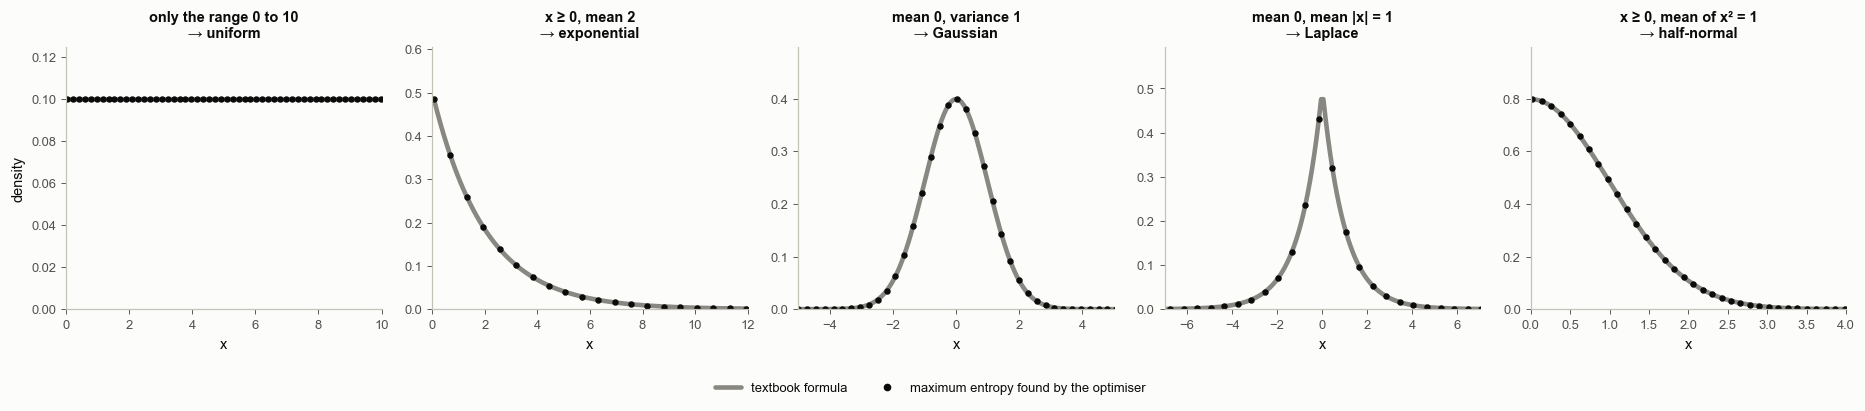

In [11]:
def maxent(x, fs, cs):
    """Maximise entropy over all distributions on the cell-centred grid x subject to sum p f_k(x) = c_k.
    p = softmax(theta) keeps p positive and normalised; theta is unrestricted. Returns the density."""
    n, dx = x.size, x[1] - x[0]
    F = jnp.asarray(np.vstack([f(x) for f in fs])) if fs else None
    scale = [float(np.abs(f(x)).max()) for f in fs]
    negH = jax.jit(lambda t: jnp.sum(jax.nn.softmax(t) * jax.nn.log_softmax(t)))
    gH = jax.jit(jax.grad(lambda t: jnp.sum(jax.nn.softmax(t) * jax.nn.log_softmax(t))))
    cons = []
    for k in range(len(fs)):
        ck = jax.jit(lambda t, k=k: (F[k] @ jax.nn.softmax(t) - cs[k]) / scale[k])
        gk = jax.jit(jax.grad(lambda t, k=k: (F[k] @ jax.nn.softmax(t) - cs[k]) / scale[k]))
        cons.append({"type": "eq", "fun": lambda t, ck=ck: float(ck(t)), "jac": lambda t, gk=gk: np.asarray(gk(t))})
    r = minimize(lambda t: float(negH(t)), np.zeros(n), jac=lambda t: np.asarray(gH(t)), constraints=cons,
                 method="SLSQP", options=dict(maxiter=4000, ftol=1e-15))
    return np.asarray(jax.nn.softmax(jnp.asarray(r.x))) / dx, r.success


def cells(a, b, n):
    e = np.linspace(a, b, n + 1)
    return 0.5 * (e[1:] + e[:-1])


cases = [
    ("only the range 0 to 10", cells(0, 10, 160), [], [], lambda x: np.full_like(x, 0.1), "uniform"),
    ("x ≥ 0, mean 2", cells(0, 30, 240), [lambda x: x], [2.0], lambda x: np.exp(-x / 2) / 2, "exponential"),
    ("mean 0, variance 1", cells(-7, 7, 200), [lambda x: x, lambda x: x ** 2], [0.0, 1.0], lambda x: norm.pdf(x), "Gaussian"),
    ("mean 0, mean |x| = 1", cells(-14, 14, 280), [lambda x: x, lambda x: np.abs(x)], [0.0, 1.0], lambda x: 0.5 * np.exp(-np.abs(x)), "Laplace"),
    ("x ≥ 0, mean of x² = 1", cells(0, 6, 150), [lambda x: x ** 2], [1.0], lambda x: 2 * norm.pdf(x), "half-normal"),
]
fig, axs = plt.subplots(1, 5, figsize=(17, 3.6))
print(f"{'constraint':24s} {'family':12s} {'optimiser converged':>20s} {'max difference / peak':>23s}")
for ax, (title, x, fs, cs, ana, fam) in zip(axs, cases):
    dens, ok = maxent(x, fs, cs)
    a = ana(x)
    ax.plot(x, a, color=S.MUTED, lw=3)
    step = max(1, x.size // 45)
    ax.plot(x[::step], dens[::step], "o", color=S.INK, ms=3.2)
    ax.set_title(f"{title}\n→ {fam}", fontsize=9.5)
    ax.set_xlabel("x")
    ax.set_ylim(0, a.max() * 1.25)
    print(f"{title:24s} {fam:12s} {str(ok):>20s} {np.abs(dens - a).max() / a.max():23.2e}")
axs[0].set_ylabel("density")
for ax, lim in zip(axs, [(0, 10), (0, 12), (-5, 5), (-7, 7), (0, 4)]):
    ax.set_xlim(*lim)
from matplotlib.lines import Line2D
fig.legend(handles=[Line2D([], [], color=S.MUTED, lw=3, label="textbook formula"),
                    Line2D([], [], color=S.INK, marker="o", ls="", ms=4, label="maximum entropy found by the optimiser")],
           loc="lower center", ncol=2, fontsize=8.5, bbox_to_anchor=(0.5, -0.04))
fig.tight_layout(rect=(0, 0.06, 1, 1))
bk.savefig(fig, "2-27_maximum_entropy")
plt.show()

**How to read it.** Grey lines are the textbook formulas; black dots are what the optimiser found when told only the
constraint in each title. They coincide (the printed differences are small fractions of each peak), so each familiar
distribution is exactly "what you get if you know this and nothing else".

**Worked example.** Three distributions with the same mean (0) and the same variance (1 m²): the Gaussian, the Laplace
and the uniform. All three respect what we know about the spread, but they make different extra assumptions.

In [12]:
b_lap = 1 / np.sqrt(2)                                   # Laplace scale with variance 1
w_uni = np.sqrt(12)                                      # uniform width with variance 1
print(f"Gaussian, sd 1:               H = 1/2 log2(2 pi e)   = {0.5 * np.log2(2 * np.pi * np.e):.4f} bits")
print(f"Laplace, b = 1/sqrt(2):       H = log2(2 e b)        = {np.log2(2 * np.e * b_lap):.4f} bits")
print(f"uniform, width sqrt(12):      H = log2(width)        = {np.log2(w_uni):.4f} bits")

Gaussian, sd 1:               H = 1/2 log2(2 pi e)   = 2.0471 bits
Laplace, b = 1/sqrt(2):       H = log2(2 e b)        = 1.9427 bits
uniform, width sqrt(12):      H = log2(width)        = 1.7925 bits


For a fixed variance the Gaussian has the largest entropy: it is the least committal noise model when the variance
is all you know. A Laplace or uniform noise model with the same variance claims extra structure (a sharp centre and
long tails, or hard limits) that needs justifying.

**Common misreadings.**
* "Maximum entropy means the widest possible distribution." It means the most spread out *in the entropy sense,
  given the constraints*: the three distributions in the worked example have exactly the same variance.
* "A Gaussian prior is an assumption of Gaussianity in the Earth." It is the least committal summary of a mean and
  a variance; the posterior can still be far from Gaussian (notebooks 2.02 and 2.25).

## Summary

| quantity | plain meaning | formula |
|---|---|---|
| entropy $H$ | average yes/no questions to find the outcome | $-\sum p_i\log_2 p_i$ |
| differential entropy | questions to know a continuous value to a given precision, minus a constant | $\tfrac12\log_2(2\pi e\sigma^2)$ for a Gaussian |
| expected information gain (mutual information) | how many times the data halve the uncertainty, on average over possible data | $H(\text{prior}) - H(\text{posterior})$ (linear-Gaussian) |
| realised information of one datum | what this particular datum taught, including how far it moved the mean | $D_{KL}(\text{posterior}\,\|\,\text{prior})$ (2.28) |
| mutual information (linear-Gaussian) | total information the data can provide, before measuring | $\sum_i \tfrac12\log_2(1 + s_i^2)$ |
| maximum entropy | the least committal distribution consistent with what you know | $p \propto \exp(\sum\lambda_k f_k)$ |

**In practice.**
* The per-patch information gain is a resolution map in bits, a companion to the posterior-sd ratio and the
  resolution matrix of notebook 2.33. The total (expected) gain is the number to compare between station networks or
  data sets, and it can be computed before any data are collected.
* The prior decides where the bits can show up: a correlated (e.g. Matérn) slip prior spreads what is learned about
  one patch to its neighbours, as in section 4 with ℓ = 5 km.
* A Gaussian noise model with a per-data-set σ is the maximum-entropy choice when a noise variance is all you know;
  the half-normal slip prior is the maximum-entropy choice for a positive quantity with a known mean square.

Next: [**2.28 · KL divergence**](2-28_kl_divergence.ipynb).